In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [10]:
EQ = '..//data//22_열처리.csv'   # timestamp·설비·제어출력·소입로온도

In [11]:
# ── [개념] 시간 인덱스 + asfreq/resample 결측 (설비센서) ────────────────────
df = pd.read_csv(EQ)
df['timestamp'] = pd.to_datetime(df['timestamp'], format='%Y-%m-%d %H:%M:%S', errors='coerce')

In [6]:
df['timestamp']

0     2024-03-01 09:00:00
1     2024-03-01 09:00:10
2     2024-03-01 09:00:20
3     2024-03-01 09:00:30
4     2024-03-01 09:00:40
              ...        
183   2024-03-01 09:32:30
184   2024-03-01 09:32:40
185   2024-03-01 09:32:50
186   2024-03-01 09:33:00
187   2024-03-01 09:33:10
Name: timestamp, Length: 188, dtype: datetime64[us]

In [12]:
df.index

RangeIndex(start=0, stop=188, step=1)

In [13]:
df['timestamp'].diff()

0                 NaT
1     0 days 00:00:10
2     0 days 00:00:10
3     0 days 00:00:10
4     0 days 00:00:10
            ...      
183   0 days 00:00:10
184   0 days 00:00:10
185   0 days 00:00:10
186   0 days 00:00:10
187   0 days 00:00:10
Name: timestamp, Length: 188, dtype: timedelta64[us]

In [14]:
df = df.set_index('timestamp')

In [16]:
df.index

DatetimeIndex(['2024-03-01 09:00:00', '2024-03-01 09:00:10',
               '2024-03-01 09:00:20', '2024-03-01 09:00:30',
               '2024-03-01 09:00:40', '2024-03-01 09:00:50',
               '2024-03-01 09:01:00', '2024-03-01 09:01:10',
               '2024-03-01 09:01:20', '2024-03-01 09:01:30',
               ...
               '2024-03-01 09:31:40', '2024-03-01 09:31:50',
               '2024-03-01 09:32:00', '2024-03-01 09:32:10',
               '2024-03-01 09:32:20', '2024-03-01 09:32:30',
               '2024-03-01 09:32:40', '2024-03-01 09:32:50',
               '2024-03-01 09:33:00', '2024-03-01 09:33:10'],
              dtype='datetime64[us]', name='timestamp', length=188, freq=None)

In [18]:
df.index.diff().value_counts()

timestamp
0 days 00:00:10      170
0 days 00:00:20        5
0 days 00:00:07        3
0 days 00:00:14        2
0 days 00:00:21        1
0 days 00:00:17        1
0 days 00:00:12        1
0 days 00:00:13        1
0 days 00:00:03        1
-1 days +23:59:55      1
0 days 00:01:20        1
Name: count, dtype: int64

In [19]:
type(df.index)

pandas.DatetimeIndex

In [20]:
df.index.to_series()

timestamp
2024-03-01 09:00:00   2024-03-01 09:00:00
2024-03-01 09:00:10   2024-03-01 09:00:10
2024-03-01 09:00:20   2024-03-01 09:00:20
2024-03-01 09:00:30   2024-03-01 09:00:30
2024-03-01 09:00:40   2024-03-01 09:00:40
                              ...        
2024-03-01 09:32:30   2024-03-01 09:32:30
2024-03-01 09:32:40   2024-03-01 09:32:40
2024-03-01 09:32:50   2024-03-01 09:32:50
2024-03-01 09:33:00   2024-03-01 09:33:00
2024-03-01 09:33:10   2024-03-01 09:33:10
Name: timestamp, Length: 188, dtype: datetime64[us]

In [21]:
type(df.index.to_series())

pandas.Series

In [22]:
df.index.to_series().diff()

timestamp
2024-03-01 09:00:00               NaT
2024-03-01 09:00:10   0 days 00:00:10
2024-03-01 09:00:20   0 days 00:00:10
2024-03-01 09:00:30   0 days 00:00:10
2024-03-01 09:00:40   0 days 00:00:10
                            ...      
2024-03-01 09:32:30   0 days 00:00:10
2024-03-01 09:32:40   0 days 00:00:10
2024-03-01 09:32:50   0 days 00:00:10
2024-03-01 09:33:00   0 days 00:00:10
2024-03-01 09:33:10   0 days 00:00:10
Name: timestamp, Length: 188, dtype: timedelta64[us]

In [23]:
df.index.to_series().diff().value_counts()

timestamp
0 days 00:00:10      170
0 days 00:00:20        5
0 days 00:00:07        3
0 days 00:00:14        2
0 days 00:00:21        1
0 days 00:00:17        1
0 days 00:00:12        1
0 days 00:00:13        1
0 days 00:00:03        1
-1 days +23:59:55      1
0 days 00:01:20        1
Name: count, dtype: int64

In [27]:
df.index.to_series().diff().dt.total_seconds()

timestamp
2024-03-01 09:00:00     NaN
2024-03-01 09:00:10    10.0
2024-03-01 09:00:20    10.0
2024-03-01 09:00:30    10.0
2024-03-01 09:00:40    10.0
                       ... 
2024-03-01 09:32:30    10.0
2024-03-01 09:32:40    10.0
2024-03-01 09:32:50    10.0
2024-03-01 09:33:00    10.0
2024-03-01 09:33:10    10.0
Name: timestamp, Length: 188, dtype: float64

In [28]:
gaps=df.index.to_series().diff().dt.total_seconds()

In [30]:
gaps.value_counts().sort_index()

timestamp
-5.0       1
 3.0       1
 7.0       3
 10.0    170
 12.0      1
 13.0      1
 14.0      2
 17.0      1
 20.0      5
 21.0      1
 80.0      1
Name: count, dtype: int64

In [31]:
df.columns

Index(['설비', '제어출력', '소입로온도'], dtype='str')

In [32]:
df['제어출력']

timestamp
2024-03-01 09:00:00    0.426
2024-03-01 09:00:10    0.463
2024-03-01 09:00:20    0.438
2024-03-01 09:00:30    0.445
2024-03-01 09:00:40    0.421
                       ...  
2024-03-01 09:32:30    0.800
2024-03-01 09:32:40    0.800
2024-03-01 09:32:50    0.800
2024-03-01 09:33:00    0.800
2024-03-01 09:33:10    0.800
Name: 제어출력, Length: 188, dtype: float64

In [33]:
df[['제어출력']]

,제어출력
timestamp,
2024-03-01 09:00:00,0.426
2024-03-01 09:00:10,0.463
2024-03-01 09:00:20,0.438
2024-03-01 09:00:30,0.445
2024-03-01 09:00:40,0.421
...,...
2024-03-01 09:32:30,0.800
2024-03-01 09:32:40,0.800
2024-03-01 09:32:50,0.800


In [34]:
df[['제어출력']].asfreq('10s')

,제어출력
timestamp,
2024-03-01 09:00:00,0.426
2024-03-01 09:00:10,0.463
2024-03-01 09:00:20,0.438
2024-03-01 09:00:30,0.445
2024-03-01 09:00:40,0.421
...,...
2024-03-01 09:32:30,0.800
2024-03-01 09:32:40,0.800
2024-03-01 09:32:50,0.800


In [35]:
norm=df[['제어출력']].asfreq('10s')

In [41]:
norm.index

DatetimeIndex(['2024-03-01 09:00:00', '2024-03-01 09:00:10',
               '2024-03-01 09:00:20', '2024-03-01 09:00:30',
               '2024-03-01 09:00:40', '2024-03-01 09:00:50',
               '2024-03-01 09:01:00', '2024-03-01 09:01:10',
               '2024-03-01 09:01:20', '2024-03-01 09:01:30',
               ...
               '2024-03-01 09:31:40', '2024-03-01 09:31:50',
               '2024-03-01 09:32:00', '2024-03-01 09:32:10',
               '2024-03-01 09:32:20', '2024-03-01 09:32:30',
               '2024-03-01 09:32:40', '2024-03-01 09:32:50',
               '2024-03-01 09:33:00', '2024-03-01 09:33:10'],
              dtype='datetime64[us]', name='timestamp', length=200, freq='10s')

In [42]:
gaps_norm=norm.index.to_series().diff().dt.total_seconds()

In [43]:
gaps_norm.value_counts().sort_index()

timestamp
10.0    199
Name: count, dtype: int64

In [36]:
df.isna().sum()

설비       0
제어출력     0
소입로온도    0
dtype: int64

In [40]:
norm.isna().sum()

제어출력    22
dtype: int64

In [38]:
df.iloc[13:18]

,설비,제어출력,소입로온도
timestamp,,,
2024-03-01 09:02:10,1,0.393,861.31
2024-03-01 09:02:20,1,0.401,861.31
2024-03-01 09:02:40,1,0.409,861.31
2024-03-01 09:02:50,1,0.387,861.38
2024-03-01 09:03:00,1,0.394,861.38


In [39]:
norm.iloc[13:18]

,제어출력
timestamp,
2024-03-01 09:02:10,0.393
2024-03-01 09:02:20,0.401
2024-03-01 09:02:30,NaN
2024-03-01 09:02:40,0.409
2024-03-01 09:02:50,0.387


In [44]:
# 다시 정리

In [45]:
# ── [개념] 시간 인덱스 + asfreq/resample 결측 (설비센서) ────────────────────
df = pd.read_csv(EQ)
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.set_index('timestamp').sort_index()
norm0 = df[['제어출력']].asfreq('10s')
print('asfreq 10s 행:', len(norm0), '빈 칸:', int(norm0['제어출력'].isna().sum()))   # 200, 22
print('resample 10s 빈 칸:', int(df[['제어출력']].resample('10s').mean()['제어출력'].isna().sum()))  # 16

asfreq 10s 행: 200 빈 칸: 22
resample 10s 빈 칸: 16


In [46]:
df[['제어출력']].resample('10s')

In [47]:
list(df[['제어출력']].resample('10s'))

[(Timestamp('2024-03-01 09:00:00'),
                        제어출력
  timestamp                 
  2024-03-01 09:00:00  0.426),
 (Timestamp('2024-03-01 09:00:10'),
                        제어출력
  timestamp                 
  2024-03-01 09:00:10  0.463),
 (Timestamp('2024-03-01 09:00:20'),
                        제어출력
  timestamp                 
  2024-03-01 09:00:20  0.438),
 (Timestamp('2024-03-01 09:00:30'),
                        제어출력
  timestamp                 
  2024-03-01 09:00:30  0.445),
 (Timestamp('2024-03-01 09:00:40'),
                        제어출력
  timestamp                 
  2024-03-01 09:00:40  0.421),
 (Timestamp('2024-03-01 09:00:50'),
                        제어출력
  timestamp                 
  2024-03-01 09:00:50  0.428),
 (Timestamp('2024-03-01 09:01:00'),
                        제어출력
  timestamp                 
  2024-03-01 09:01:00  0.405),
 (Timestamp('2024-03-01 09:01:10'),
                        제어출력
  timestamp                 
  2024-03-01 09:01:10  0.443),


In [49]:
df[['제어출력']].resample('10s').mean()

,제어출력
timestamp,
2024-03-01 09:00:00,0.426
2024-03-01 09:00:10,0.463
2024-03-01 09:00:20,0.438
2024-03-01 09:00:30,0.445
2024-03-01 09:00:40,0.421
...,...
2024-03-01 09:32:30,0.800
2024-03-01 09:32:40,0.800
2024-03-01 09:32:50,0.800


In [51]:
df[['제어출력']].resample('10s').mean().mean()

제어출력    0.610557
dtype: float64

In [52]:
norm0['제어출력'].resample('10s').mean().mean()

np.float64(0.6183988764044944)

In [50]:
norm0['제어출력'].resample('10s').mean()

timestamp
2024-03-01 09:00:00    0.426
2024-03-01 09:00:10    0.463
2024-03-01 09:00:20    0.438
2024-03-01 09:00:30    0.445
2024-03-01 09:00:40    0.421
                       ...  
2024-03-01 09:32:30    0.800
2024-03-01 09:32:40    0.800
2024-03-01 09:32:50    0.800
2024-03-01 09:33:00    0.800
2024-03-01 09:33:10    0.800
Freq: 10s, Name: 제어출력, Length: 200, dtype: float64

In [53]:
# 실습1 10시 30분까지

In [54]:
#  두 센서 '제어출력', '소입로온도

In [55]:
# 제어 출력 누락때문에 빈칸 16개 맞는지 확인

In [56]:
# ── [실습 1] 시간 인덱스와 1분 리샘플링 재확인 ──────────────────────────────
df = pd.read_csv(EQ)
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.set_index('timestamp').sort_index()

In [57]:
one_min = df[['제어출력', '소입로온도']].resample('1min').mean()

In [58]:
print(one_min.head(3).round(2))

                     제어출력   소입로온도
timestamp                        
2024-03-01 09:00:00  0.44  861.06
2024-03-01 09:01:00  0.42  861.18
2024-03-01 09:02:00  0.40  861.31


In [59]:
print('1분 평균 빈 칸:', int(one_min['제어출력'].isna().sum()))   # 16

1분 평균 빈 칸: 1


In [60]:
# unixtime 변환 

In [61]:
from datetime import datetime, timezone

In [65]:
unix_time = 1793756430  # 예시

In [63]:
timezone.utc

datetime.timezone.utc

In [67]:
from zoneinfo import ZoneInfo

In [68]:
print(datetime.fromtimestamp(unix_time, ZoneInfo("Asia/Seoul")))

2026-11-04 10:40:30+09:00


In [69]:
# 실습2 10시 50분까지

In [70]:
# ── [실습 2] 측정 간격 분포로 주기 진단 ─────────────────────────────────────
gaps = df.index.to_series().diff().dt.total_seconds()
print(gaps.value_counts().sort_index().head().to_dict())   # {3.0:1, 5.0:2, 7.0:3, 9.0:1, 10.0:169}
print('최대 간격(초):', gaps.max())                          # 80.0

{3.0: 1, 5.0: 2, 7.0: 3, 9.0: 1, 10.0: 169}
최대 간격(초): 80.0


In [72]:
# 실습3 11시 13분까지 제어출력', '소입로온도'

In [73]:
# ── [실습 3] asfreq로 정규화 후 NaN 확인 ────────────────────────────────────
cols = ['제어출력', '소입로온도']
norm = df[cols].asfreq('10s')
print('총 행:', len(norm))                                  # 200
print(norm.isna().sum().to_dict())                          # {'제어출력':22,'소입로온도':22}


총 행: 200
{'제어출력': 22, '소입로온도': 22}


In [74]:
norm[norm.isna()]

,제어출력,소입로온도
timestamp,,
2024-03-01 09:00:00,NaN,NaN
2024-03-01 09:00:10,NaN,NaN
2024-03-01 09:00:20,NaN,NaN
2024-03-01 09:00:30,NaN,NaN
2024-03-01 09:00:40,NaN,NaN
...,...,...
2024-03-01 09:32:30,NaN,NaN
2024-03-01 09:32:40,NaN,NaN
2024-03-01 09:32:50,NaN,NaN


In [75]:
help(df[cols].asfreq)

Help on method asfreq in module pandas.core.generic:

asfreq(
    freq: Frequency,
    method: FillnaOptions | None = None,
    how: Literal['start', 'end'] | None = None,
    normalize: bool = False,
    fill_value: Hashable | None = None
) -> Self method of pandas.DataFrame instance
    Convert time series to specified frequency.

    Returns the original data conformed to a new index with the specified
    frequency.

    If the index of this Series/DataFrame is a :class:`~pandas.PeriodIndex`, the
    new index is the result of transforming the original index with
    :meth:`PeriodIndex.asfreq <pandas.PeriodIndex.asfreq>` (so the original index
    will map one-to-one to the new index).

    Otherwise, the new index will be equivalent to ``pd.date_range(start, end,
    freq=freq)`` where ``start`` and ``end`` are, respectively, the min and
    max entries in the original index (see :func:`pandas.date_range`). The
    values corresponding to any timesteps in the new index which were 

In [76]:
filled = df[cols].asfreq('10s', method='ffill')

In [77]:
filled

,제어출력,소입로온도
timestamp,,
2024-03-01 09:00:00,0.426,861.05
2024-03-01 09:00:10,0.463,860.99
2024-03-01 09:00:20,0.438,861.05
2024-03-01 09:00:30,0.445,861.05
2024-03-01 09:00:40,0.421,861.11
...,...,...
2024-03-01 09:32:30,0.800,857.16
2024-03-01 09:32:40,0.800,857.16
2024-03-01 09:32:50,0.800,857.10


In [78]:
print('ffill 후:', filled.isna().sum().to_dict())            # 둘 다 0

ffill 후: {'제어출력': 0, '소입로온도': 0}


In [83]:
df.columns

Index(['설비', '제어출력', '소입로온도'], dtype='str')

In [84]:
df.head()

,설비,제어출력,소입로온도
timestamp,,,
2024-03-01 09:00:00,1,0.426,861.05
2024-03-01 09:00:10,1,0.463,860.99
2024-03-01 09:00:20,1,0.438,861.05
2024-03-01 09:00:30,1,0.445,861.05
2024-03-01 09:00:40,1,0.421,861.11


In [85]:
# df['제어출력']

In [87]:
EQ = '..//data//22_열처리.csv'   # timestamp·설비·제어출력·소입로온도

In [88]:
df = pd.read_csv(EQ)

In [89]:
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.set_index('timestamp').sort_index()

In [91]:
df.columns

Index(['설비', '제어출력', '소입로온도'], dtype='str')

In [92]:
df[['제어출력']]

,제어출력
timestamp,
2024-03-01 09:00:00,0.426
2024-03-01 09:00:10,0.463
2024-03-01 09:00:20,0.438
2024-03-01 09:00:30,0.445
2024-03-01 09:00:40,0.421
...,...
2024-03-01 09:32:30,0.800
2024-03-01 09:32:40,0.800
2024-03-01 09:32:50,0.800


In [93]:
norm0 = df[['제어출력']].asfreq('10s')

In [94]:
norm0 

,제어출력
timestamp,
2024-03-01 09:00:00,0.426
2024-03-01 09:00:10,0.463
2024-03-01 09:00:20,0.438
2024-03-01 09:00:30,0.445
2024-03-01 09:00:40,0.421
...,...
2024-03-01 09:32:30,0.800
2024-03-01 09:32:40,0.800
2024-03-01 09:32:50,0.800


In [95]:
plt.rcParams['font.family']='Malgun Gothic'

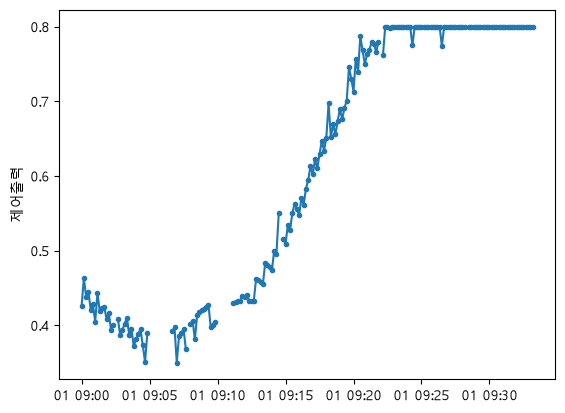

In [98]:
# 점 + 선으로 함께 그려야 빈 구간이 보임
plt.rcParams['font.family']='Malgun Gothic'
plt.plot(norm.index, norm["제어출력"], marker=".")
plt.ylabel("제어출력")
plt.show()

In [99]:
# 실습4 11시 31분

In [100]:
# '제어출력', '소입로온도'

In [102]:
norm = df[['제어출력', '소입로온도']].asfreq('10s')

In [103]:
print('결측 개수:', norm.isna().sum().to_dict())              # 22, 22

결측 개수: {'제어출력': 22, '소입로온도': 22}


In [104]:
print('결측 비율(%):', (norm.isna().mean() * 100).round(1).to_dict())  # 11.0, 11.0

결측 비율(%): {'제어출력': 11.0, '소입로온도': 11.0}


In [105]:
miss = norm[norm['제어출력'].isna()].index

In [106]:
print('빈 시각 개수:', len(miss), '/ 첫 구간:', miss[0])       # 22 / 2024-03-01 09:02:30

빈 시각 개수: 22 / 첫 구간: 2024-03-01 09:02:30


In [107]:
# 실습5,6 11시 43분까지

In [109]:
df.columns

Index(['설비', '제어출력', '소입로온도'], dtype='str')

In [113]:
df.head()

,설비,제어출력,소입로온도
timestamp,,,
2024-03-01 09:00:00,1,0.426,861.05
2024-03-01 09:00:10,1,0.463,860.99
2024-03-01 09:00:20,1,0.438,861.05
2024-03-01 09:00:30,1,0.445,861.05
2024-03-01 09:00:40,1,0.421,861.11


In [111]:
# 컬럼명 바꾸기 연습

In [112]:
df.rename(columns={'설비':'설비2'})

,설비2,제어출력,소입로온도
timestamp,,,
2024-03-01 09:00:00,1,0.426,861.05
2024-03-01 09:00:10,1,0.463,860.99
2024-03-01 09:00:20,1,0.438,861.05
2024-03-01 09:00:30,1,0.445,861.05
2024-03-01 09:00:40,1,0.421,861.11
...,...,...,...
2024-03-01 09:32:30,1,0.800,857.16
2024-03-01 09:32:40,1,0.800,857.16
2024-03-01 09:32:50,1,0.800,857.10


In [108]:
df[['제어출력']].asfreq('10s')

,제어출력
timestamp,
2024-03-01 09:00:00,0.426
2024-03-01 09:00:10,0.463
2024-03-01 09:00:20,0.438
2024-03-01 09:00:30,0.445
2024-03-01 09:00:40,0.421
...,...
2024-03-01 09:32:30,0.800
2024-03-01 09:32:40,0.800
2024-03-01 09:32:50,0.800


In [114]:
a = df[['제어출력']].asfreq('10s').rename(columns={'제어출력': 'asfreq'})

In [115]:
a

,asfreq
timestamp,
2024-03-01 09:00:00,0.426
2024-03-01 09:00:10,0.463
2024-03-01 09:00:20,0.438
2024-03-01 09:00:30,0.445
2024-03-01 09:00:40,0.421
...,...
2024-03-01 09:32:30,0.800
2024-03-01 09:32:40,0.800
2024-03-01 09:32:50,0.800


In [116]:
r = df[['제어출력']].resample('10s').mean().rename(columns={'제어출력': 'resample'})

In [119]:
a,r

(                     asfreq
 timestamp                  
 2024-03-01 09:00:00   0.426
 2024-03-01 09:00:10   0.463
 2024-03-01 09:00:20   0.438
 2024-03-01 09:00:30   0.445
 2024-03-01 09:00:40   0.421
 ...                     ...
 2024-03-01 09:32:30   0.800
 2024-03-01 09:32:40   0.800
 2024-03-01 09:32:50   0.800
 2024-03-01 09:33:00   0.800
 2024-03-01 09:33:10   0.800
 
 [200 rows x 1 columns],
                      resample
 timestamp                    
 2024-03-01 09:00:00     0.426
 2024-03-01 09:00:10     0.463
 2024-03-01 09:00:20     0.438
 2024-03-01 09:00:30     0.445
 2024-03-01 09:00:40     0.421
 ...                       ...
 2024-03-01 09:32:30     0.800
 2024-03-01 09:32:40     0.800
 2024-03-01 09:32:50     0.800
 2024-03-01 09:33:00     0.800
 2024-03-01 09:33:10     0.800
 
 [200 rows x 1 columns])

In [121]:
a.columns

Index(['asfreq'], dtype='str')

In [122]:
a.index

DatetimeIndex(['2024-03-01 09:00:00', '2024-03-01 09:00:10',
               '2024-03-01 09:00:20', '2024-03-01 09:00:30',
               '2024-03-01 09:00:40', '2024-03-01 09:00:50',
               '2024-03-01 09:01:00', '2024-03-01 09:01:10',
               '2024-03-01 09:01:20', '2024-03-01 09:01:30',
               ...
               '2024-03-01 09:31:40', '2024-03-01 09:31:50',
               '2024-03-01 09:32:00', '2024-03-01 09:32:10',
               '2024-03-01 09:32:20', '2024-03-01 09:32:30',
               '2024-03-01 09:32:40', '2024-03-01 09:32:50',
               '2024-03-01 09:33:00', '2024-03-01 09:33:10'],
              dtype='datetime64[us]', name='timestamp', length=200, freq='10s')

In [123]:
pd.merge(a,r, on=a.index)

,key_0,asfreq,resample
0,2024-03-01 09:00:00,0.426,0.426
1,2024-03-01 09:00:10,0.463,0.463
2,2024-03-01 09:00:20,0.438,0.438
3,2024-03-01 09:00:30,0.445,0.445
4,2024-03-01 09:00:40,0.421,0.421
...,...,...,...
195,2024-03-01 09:32:30,0.800,0.800
196,2024-03-01 09:32:40,0.800,0.800
197,2024-03-01 09:32:50,0.800,0.800
198,2024-03-01 09:33:00,0.800,0.800


In [124]:
a.join(r)

,asfreq,resample
timestamp,,
2024-03-01 09:00:00,0.426,0.426
2024-03-01 09:00:10,0.463,0.463
2024-03-01 09:00:20,0.438,0.438
2024-03-01 09:00:30,0.445,0.445
2024-03-01 09:00:40,0.421,0.421
...,...,...
2024-03-01 09:32:30,0.800,0.800
2024-03-01 09:32:40,0.800,0.800
2024-03-01 09:32:50,0.800,0.800


In [125]:
print('asfreq:', int(a['asfreq'].isna().sum()), '/ resample:', int(r['resample'].isna().sum()))  # 22 / 16

asfreq: 22 / resample: 16


In [126]:
down = df[['제어출력']].resample('1min').mean()

In [127]:
print('1분 다운샘플링:', int(down['제어출력'].isna().sum()))   # 1

1분 다운샘플링: 1


In [128]:
# 실습6

In [129]:
norm = df[['제어출력', '소입로온도']].asfreq('10s')

In [130]:
print('측정 기간:', norm.index.min(), '~', norm.index.max())

측정 기간: 2024-03-01 09:00:00 ~ 2024-03-01 09:33:10


In [131]:
print('시점 수:', len(norm), '/ 결측:', norm.isna().sum().to_dict())
print('결측 비율(%):', (norm.isna().mean() * 100).round(1).to_dict())

시점 수: 200 / 결측: {'제어출력': 22, '소입로온도': 22}
결측 비율(%): {'제어출력': 11.0, '소입로온도': 11.0}


In [133]:
norm['제어출력'].isna()

timestamp
2024-03-01 09:00:00    False
2024-03-01 09:00:10    False
2024-03-01 09:00:20    False
2024-03-01 09:00:30    False
2024-03-01 09:00:40    False
                       ...  
2024-03-01 09:32:30    False
2024-03-01 09:32:40    False
2024-03-01 09:32:50    False
2024-03-01 09:33:00    False
2024-03-01 09:33:10    False
Freq: 10s, Name: 제어출력, Length: 200, dtype: bool

In [134]:
isna=norm['제어출력'].isna()

In [135]:
isna.to_csv('isna.csv')

In [136]:
isna

timestamp
2024-03-01 09:00:00    False
2024-03-01 09:00:10    False
2024-03-01 09:00:20    False
2024-03-01 09:00:30    False
2024-03-01 09:00:40    False
                       ...  
2024-03-01 09:32:30    False
2024-03-01 09:32:40    False
2024-03-01 09:32:50    False
2024-03-01 09:33:00    False
2024-03-01 09:33:10    False
Freq: 10s, Name: 제어출력, Length: 200, dtype: bool

In [138]:
isna.shift()

timestamp
2024-03-01 09:00:00      NaN
2024-03-01 09:00:10    False
2024-03-01 09:00:20    False
2024-03-01 09:00:30    False
2024-03-01 09:00:40    False
                       ...  
2024-03-01 09:32:30    False
2024-03-01 09:32:40    False
2024-03-01 09:32:50    False
2024-03-01 09:33:00    False
2024-03-01 09:33:10    False
Freq: 10s, Name: 제어출력, Length: 200, dtype: object

In [139]:
isna.shift().cumsum()

timestamp
2024-03-01 09:00:00     NaN
2024-03-01 09:00:10     0.0
2024-03-01 09:00:20     0.0
2024-03-01 09:00:30     0.0
2024-03-01 09:00:40     0.0
                       ... 
2024-03-01 09:32:30    22.0
2024-03-01 09:32:40    22.0
2024-03-01 09:32:50    22.0
2024-03-01 09:33:00    22.0
2024-03-01 09:33:10    22.0
Freq: 10s, Name: 제어출력, Length: 200, dtype: object

In [140]:
isna != isna.shift().cumsum()

timestamp
2024-03-01 09:00:00     True
2024-03-01 09:00:10    False
2024-03-01 09:00:20    False
2024-03-01 09:00:30    False
2024-03-01 09:00:40    False
                       ...  
2024-03-01 09:32:30     True
2024-03-01 09:32:40     True
2024-03-01 09:32:50     True
2024-03-01 09:33:00     True
2024-03-01 09:33:10     True
Freq: 10s, Name: 제어출력, Length: 200, dtype: bool

In [141]:
(isna != isna.shift()).cumsum()

timestamp
2024-03-01 09:00:00     1
2024-03-01 09:00:10     1
2024-03-01 09:00:20     1
2024-03-01 09:00:30     1
2024-03-01 09:00:40     1
                       ..
2024-03-01 09:32:30    15
2024-03-01 09:32:40    15
2024-03-01 09:32:50    15
2024-03-01 09:33:00    15
2024-03-01 09:33:10    15
Freq: 10s, Name: 제어출력, Length: 200, dtype: int64

In [142]:
groups=(isna != isna.shift()).cumsum()

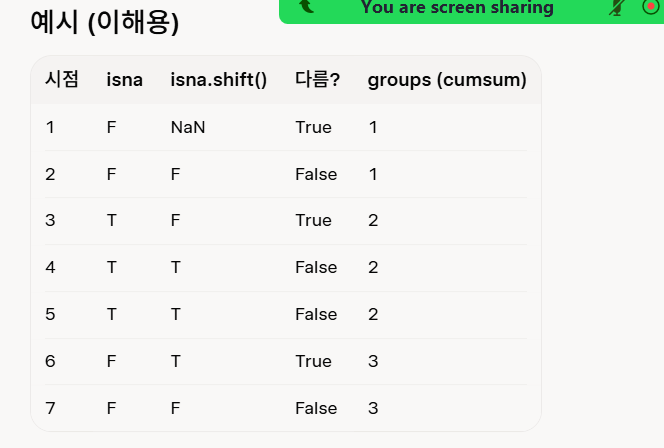

In [143]:
print('가장 긴 연속 결측(칸):', int(isna.groupby(groups).sum().max()))   # 10

가장 긴 연속 결측(칸): 10
